In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
data = pd.read_csv("data/penguins.csv")

In [4]:
data.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [5]:
data.describe(include="all")

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,334
unique,3,3,NaN,NaN,NaN,NaN,3
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


In [6]:
for col in data.columns:
    print(f"Column: {col}")
    print(data[col].value_counts())
    print("\n")

Column: species
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


Column: island
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64


Column: culmen_length_mm
culmen_length_mm
41.1    7
45.2    6
39.6    5
37.8    5
46.5    5
       ..
41.7    1
53.4    1
55.1    1
48.8    1
49.9    1
Name: count, Length: 164, dtype: int64


Column: culmen_depth_mm
culmen_depth_mm
17.0    12
17.9    10
18.6    10
18.5    10
15.0    10
        ..
13.2     1
13.6     1
13.1     1
13.3     1
14.9     1
Name: count, Length: 80, dtype: int64


Column: flipper_length_mm
flipper_length_mm
190.0    22
195.0    17
187.0    16
193.0    15
210.0    14
191.0    13
215.0    12
197.0    10
196.0    10
185.0     9
198.0     8
216.0     8
208.0     8
220.0     8
181.0     7
192.0     7
212.0     7
230.0     7
186.0     7
184.0     7
189.0     7
188.0     6
214.0     6
201.0     6
217.0     6
213.0     6
222.0     6
199.0     6
221.0     5
218.0     

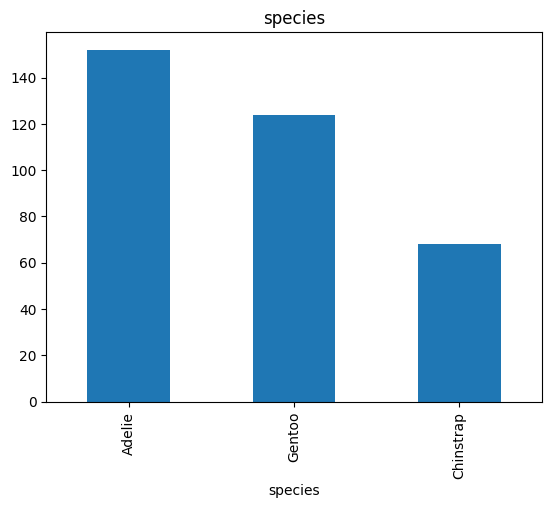

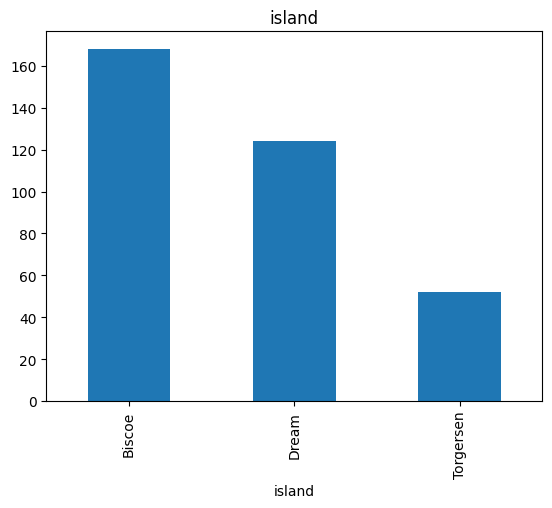

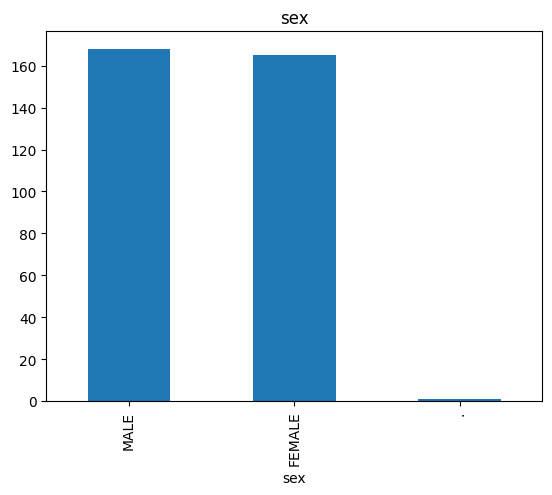

In [8]:
for col in data.columns:
    if data[col].dtype == "object":
        data[col].value_counts().plot(kind="bar")
        plt.pyplot.title(col)
        plt.pyplot.show()

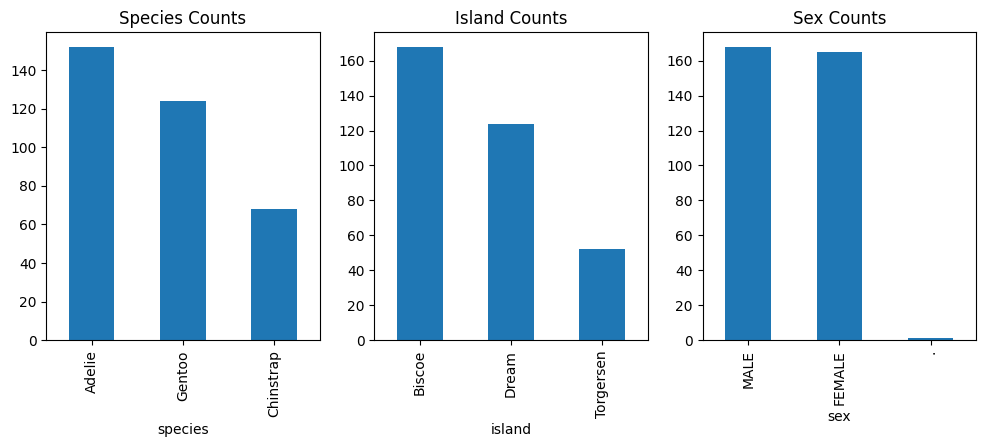

In [15]:
species_counts = data["species"].value_counts()
species_island_counts = data["island"].value_counts()
species_sex_counts = data["sex"].value_counts()


plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
species_counts.plot(kind="bar")
plt.title("Species Counts")
plt.subplot(1, 3, 2)
species_island_counts.plot(kind="bar")
plt.title("Island Counts")
plt.subplot(1, 3, 3)
species_sex_counts.plot(kind="bar")
plt.title("Sex Counts");

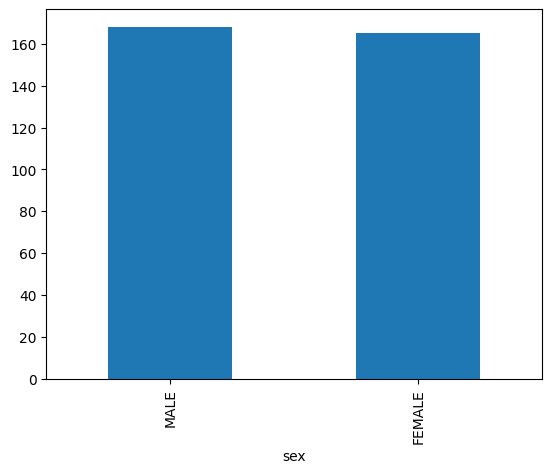

In [17]:
# Now let's replace the "." of the sex column with nan
data["sex"] = data["sex"].replace(".", np.nan)
data["sex"].value_counts().plot(kind="bar");

In [18]:
data.isnull().sum()

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [19]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="most_frequent")
data.iloc[:, :] = imputer.fit_transform(data)
data.isnull().sum()

species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [20]:
data.duplicated().sum()

np.int64(0)

In [22]:
data.corr(numeric_only=True)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000000,-0.234635,0.656856,0.595720
culmen_depth_mm,-0.234635,1.000000,-0.582472,-0.471339
flipper_length_mm,0.656856,-0.582472,1.000000,0.871302
body_mass_g,0.595720,-0.471339,0.871302,1.000000


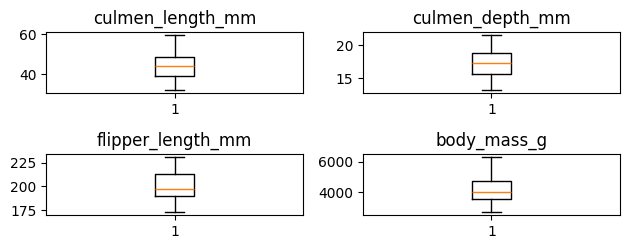

In [69]:
num_col = [col for col in data.columns if data[col].dtype != "object"]
for i, col in enumerate(num_col):
    plt.subplot(len(num_col), 2 , i + 1)
    plt.boxplot(x=data[col])
    plt.title(col)
plt.tight_layout()
plt.show()

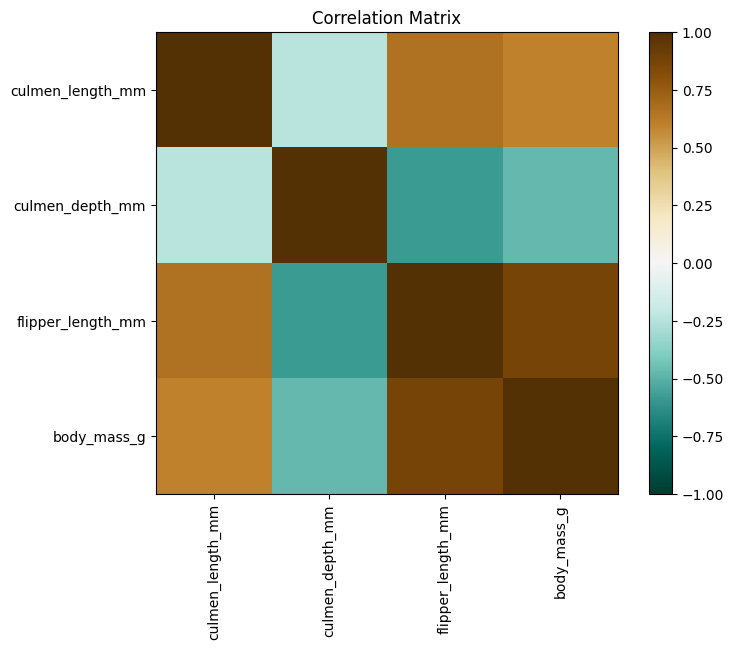

In [37]:
correlation_matrix = data.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap="BrBG_r", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlation_matrix)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix)), correlation_matrix.columns)
plt.title("Correlation Matrix")
plt.show()

In [65]:
cov_matrix = data.cov(numeric_only=True)
cov_matrix  

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,29.679415,-2.516984,50.260588,2596.971151
culmen_depth_mm,-2.516984,3.877201,-16.108849,-742.660180
flipper_length_mm,50.260588,-16.108849,197.269501,9792.552037
body_mass_g,2596.971151,-742.660180,9792.552037,640316.716388


In [70]:
data.columns

Index(['species', 'island', 'culmen_length_mm', 'culmen_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

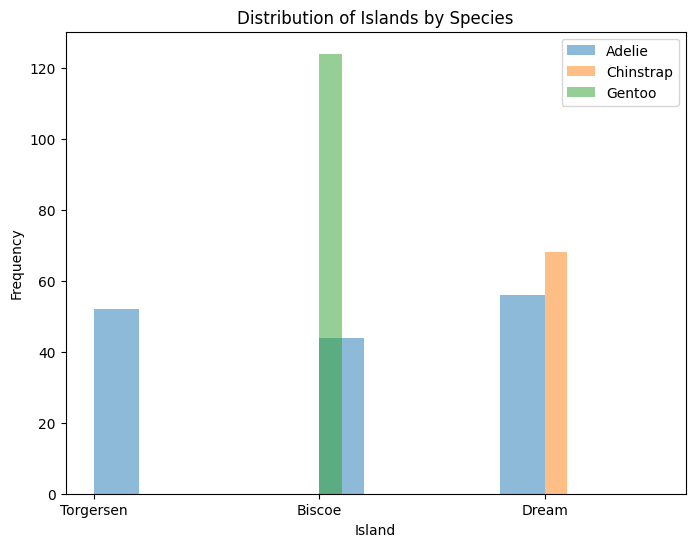

In [77]:
unique_sex = data["sex"].unique()
unique_species = data["species"].unique()

fig, ax = plt.subplots(figsize=(8, 6))
for species in unique_species:
    data_species = data[data["species"] == species]
    ax.hist(data_species["island"], label=species, alpha=0.5, bins=10)
ax.set_xlabel("Island")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Islands by Species")    
plt.legend();

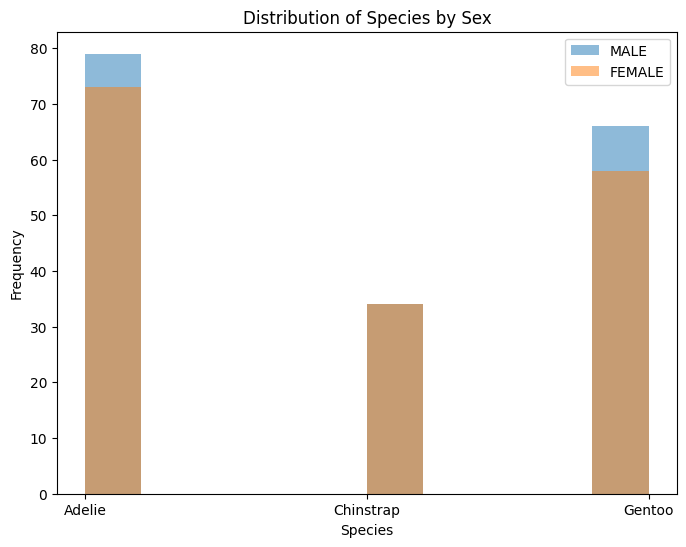

In [78]:
fig, ax = plt.subplots(figsize=(8, 6))
for sex in unique_sex:
    data_sex = data[data["sex"] == sex]
    ax.hist(data_sex["species"], label=sex, alpha=0.5, bins=10)
ax.set_xlabel("Species")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Species by Sex")
plt.legend();

In [84]:
len(data.loc[(data["sex"] == "FEMALE") & (data["species"] == "Chinstrap"), :])

34